# Step 4c — Seasonality & Shopping Festivals (Double 11, 618, Double 12)

**Question.** Do shopping festivals and promotional periods shape purchasing in a way that helps rank the test slates, and does the dataset even contain the information to build such a feature?

**What the data allows and what it doesn't.**

| Constraint | Consequence |
|---|---|
| History stores only *time gaps*, but every test query was issued on **2022-10-17** (Liu et al., 2023) | Every history event can be placed on a real calendar date: `date = 2022-10-17 − age_days`, accurate to about ±1 day |
| All 173,831 test sessions fall on **the same day** | Any calendar feature of the *session* (is-festival, days-to-Double-11, weekday) is a **constant** across all 15.5M rows, so it carries no ranking signal and the test labels can't measure a festival effect on session conversion |
| Retention windows (Step 1): clicks 7 d, carts ~90 d, orders 365 d | Only **orders** cover Double 11 2021 (age ~340 d), Double 12 2021 and 618 2022 (age ~121 d) |

So seasonality can only enter through features that **vary within a slate**: how festival-driven the candidate's **category** is, and how the **user** behaved during past festivals. The test date also gives us a natural experiment: 2022-10-17 falls a few days **before the Double 11 pre-sale opens**, so festival-sensitive categories might show *deferral*, where users browse and cart now but wait for festival prices to buy.

**Output:** four features added to `features.parquet`, a deferral hypothesis test, and a benchmark.

In [4]:
import os, time, gc
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow as pa, pyarrow.csv as pacsv

try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path('/content/drive/MyDrive/JDSearch/Raw Data')
except ImportError:
    DATA_DIR = Path(os.environ.get('JD_DATA_DIR', '~/Downloads/JDsearch')).expanduser()
OUT_DIR = DATA_DIR / 'processed'
SEED, TEST_DATE, ORD = 42, pd.Timestamp('2022-10-17'), 2

cands = pd.read_parquet(OUT_DIR / 'candidates.parquet', columns=['user', 'wid', 'label'])
events = pd.read_parquet(OUT_DIR / 'events.parquet', columns=['user', 'wid', 'type', 'age_days'])
orders = events[events['type'] == ORD].reset_index(drop=True); del events; gc.collect()
nU = int(cands['user'].max()) + 1

prod = pacsv.read_csv(DATA_DIR / 'product_meta_data.txt',
    parse_options=pacsv.ParseOptions(delimiter='\t', quote_char=False),
    convert_options=pacsv.ConvertOptions(include_columns=['wid', 'cate_id_3'],
                                         column_types={'wid': pa.int64(), 'cate_id_3': pa.int64()})).to_pandas()
prod['cate_id_3'] = prod['cate_id_3'].fillna(-1).astype(np.int64)
prod_idx = pd.Index(prod['wid'])
def cat3_of(wids):
    i = prod_idx.get_indexer(wids)
    out = prod['cate_id_3'].to_numpy()[np.maximum(i, 0)]
    out[i < 0] = -1
    return out
orders['cat3'] = cat3_of(orders['wid'])
cands['cat3'] = cat3_of(cands['wid'])
orders['date'] = TEST_DATE - pd.to_timedelta(np.floor(orders['age_days']), unit='D')
print(f'orders {len(orders):,} spanning {orders["date"].min().date()} .. {orders["date"].max().date()}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
orders 6,817,283 spanning 2021-10-18 .. 2022-10-17


## 1. Does the reconstructed calendar show the festivals?

If `date = 2022-10-17 − age_days` is right, daily order volume should spike on the known festival days. Each day is compared with its 15-day rolling median, which removes the slow upward trend: all sampled users were active on the test date, so activity naturally grows towards it.

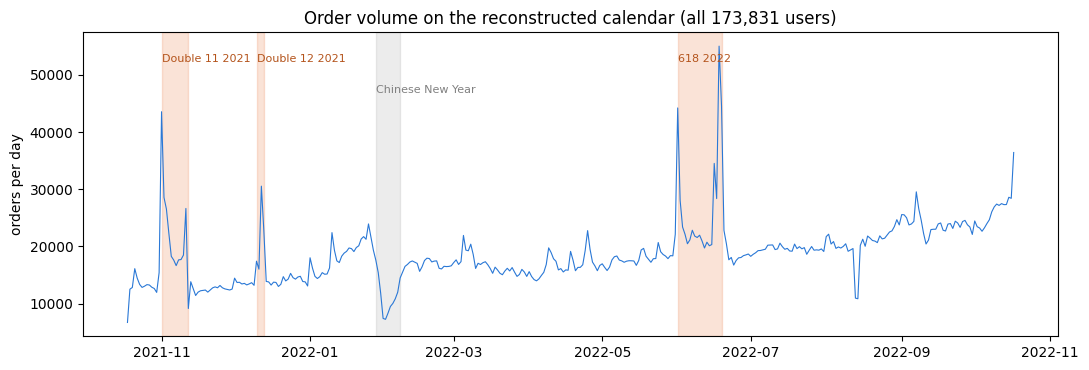

Top days vs 15-day rolling median:
date
2022-06-18    2.69
2021-11-01    2.62
2021-12-12    2.23
2022-06-19    2.19
2022-06-01    2.09
2021-12-13    1.67
2022-06-16    1.65
2021-11-02    1.62

Lowest days:
date
2021-10-18    0.52
2022-08-14    0.54
2022-08-13    0.55
2022-02-01    0.61


In [5]:
daily = orders.groupby('date').size()
ratio = (daily / daily.rolling(15, center=True, min_periods=5).median()).dropna()

FESTIVALS = {'Double 11 2021': ('2021-11-01', '2021-11-11'),
             'Double 12 2021': ('2021-12-10', '2021-12-12'),
             '618 2022':       ('2022-06-01', '2022-06-18')}
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(daily.index, daily.values, lw=0.8, color='#2a78d6')
for name, (s, e) in FESTIVALS.items():
    ax.axvspan(pd.Timestamp(s), pd.Timestamp(e) + pd.Timedelta(days=1), color='#e8743b', alpha=0.2)
    ax.text(pd.Timestamp(s), daily.max() * 0.95, name, fontsize=8, color='#b4541c')
ax.axvspan(pd.Timestamp('2022-01-28'), pd.Timestamp('2022-02-07'), color='grey', alpha=0.15)
ax.text(pd.Timestamp('2022-01-28'), daily.max() * 0.85, 'Chinese New Year', fontsize=8, color='grey')
ax.set_ylabel('orders per day'); ax.set_title('Order volume on the reconstructed calendar (all 173,831 users)')
plt.tight_layout(); plt.show()

print('Top days vs 15-day rolling median:')
print(ratio.sort_values(ascending=False).head(8).round(2).to_string())
print('\nLowest days:')
print(ratio.sort_values().head(4).round(2).to_string())

The spikes land on exactly the right dates: 618 (June 18) and its June 1 kick-off, the first Double 11 wave (Nov 1, when the 2021 sales opened) and Nov 11 itself, Double 12 (Dec 12), plus a Chinese-New-Year dip when logistics shut down. This validates the calendar reconstruction and shows festivals clearly shape purchasing on JD.

## 2. Features that can vary within a slate

Festival days are `F` = Double 11 (Nov 1–11 2021) ∪ Double 12 (Dec 10–12 2021) ∪ 618 (Jun 1–18 2022): 32 days.

| Feature | Level | Definition |
|---|---|---|
| `cat3_festival_lift` | candidate category | log of (share of the category's orders placed on festival days ÷ the same share for all orders), smoothed with 50 pseudo-orders so small categories shrink toward 0. > 0 means the category is **promotion-driven**. Because it compares a category with all orders over the same days, the overall trend cancels |
| `u_festival_share` | user (constant within a slate) | share of the user's orders placed on festival days, shrunk toward the global share (5 pseudo-orders). Identifies **festival shoppers** |
| `ucat3_fest_ord` | user × candidate category | how many orders the user placed in the candidate's category **on festival days** (did they stock up on this kind of product last festival?) |
| `ucat3_fest_share` | user × candidate category | `ucat3_fest_ord` ÷ the user's total orders in that category (NaN if none). Does the user **only** buy this category on promotion? |

In [6]:
fest_mask = np.zeros(len(orders), bool)
for s, e in FESTIVALS.values():
    fest_mask |= (orders['date'] >= s).to_numpy() & (orders['date'] <= e).to_numpy()
orders['fest'] = fest_mask
p_fest = fest_mask.mean()
print(f'festival days hold {p_fest:.1%} of all orders (32 of 365 days = {32 / 365:.1%} of the calendar)')

o3 = orders[orders['cat3'] >= 0]
g = o3.groupby('cat3')['fest'].agg(['sum', 'size'])
A_CAT = 50.0
cat_lift = np.log(((g['sum'] + A_CAT * p_fest) / (g['size'] + A_CAT)) / p_fest)

A_USER = 5.0
uf = orders.groupby('user')['fest'].agg(['sum', 'size'])
u_share = ((uf['sum'] + A_USER * p_fest) / (uf['size'] + A_USER)).reindex(range(nU)).fillna(p_fest)

C = int(max(o3['cat3'].max(), cands['cat3'].max())) + 1
uc = o3.groupby(o3['user'].to_numpy().astype(np.int64) * C + o3['cat3'].to_numpy())['fest'].agg(['sum', 'size'])
ck = cands['user'].to_numpy().astype(np.int64) * C + np.maximum(cands['cat3'].to_numpy(), 0)
has_cat = cands['cat3'].to_numpy() >= 0

SEAS = {}
SEAS['cat3_festival_lift'] = np.where(has_cat, cat_lift.reindex(cands['cat3']).fillna(0).to_numpy(), np.nan).astype(np.float32)
SEAS['u_festival_share'] = u_share.to_numpy()[cands['user'].to_numpy()].astype(np.float32)
fest_ord = uc['sum'].reindex(ck).to_numpy(np.float32)
tot_ord = uc['size'].reindex(ck).to_numpy(np.float32)
SEAS['ucat3_fest_ord'] = np.where(has_cat, np.nan_to_num(fest_ord, nan=0.0), np.nan).astype(np.float32)
SEAS['ucat3_fest_share'] = (fest_ord / tot_ord).astype(np.float32)
del o3, uc, fest_ord, tot_ord; gc.collect()

top = pd.DataFrame({'lift': cat_lift, 'orders': g['size']})
print('\nmost promotion-driven categories (>= 2,000 orders):')
print(top[top['orders'] >= 2000].sort_values('lift', ascending=False).head(5).round(3).to_string())
print('\nleast promotion-driven categories (>= 2,000 orders):')
print(top[top['orders'] >= 2000].sort_values('lift').head(5).round(3).to_string())
pd.DataFrame(SEAS).describe().T.round(3)

festival days hold 11.5% of all orders (32 of 365 days = 8.8% of the calendar)

most promotion-driven categories (>= 2,000 orders):
           lift  orders
cat3                   
90943270  0.557   12848
81086727  0.549   14114
32142466  0.520    9900
56320610  0.476   11901
5745146   0.458   14387

least promotion-driven categories (>= 2,000 orders):
           lift  orders
cat3                   
67835395 -2.507    3226
14144385 -1.066    3094
47794750 -0.944    3445
6985291  -0.935    2441
71844478 -0.896    4492


,count,mean,std,min,25%,50%,75%,max
cat3_festival_lift,15439674.0,-0.028,0.247,-2.507,-0.187,-0.046,0.106,0.915
u_festival_share,15510012.0,0.107,0.079,0.001,0.052,0.091,0.129,0.857
ucat3_fest_ord,15439674.0,0.038,0.464,0.000,0.000,0.000,0.000,96.000
ucat3_fest_share,1915201.0,0.093,0.252,0.000,0.000,0.000,0.000,1.000


## 3. Hypothesis test: pre-festival deferral on the test day

2022-10-17 falls just before the Double 11 pre-sale. If shoppers defer promotion-driven purchases to the festival, then in the test slates, candidates from **highly festival-sensitive categories** should show normal or high interest (clicks, carts) but a **lower share of interactions ending in a purchase**.

This is descriptive. `cat3_festival_lift` is built from history only, with no labels involved, so all slates can be used.

In [7]:
lab = cands['label'].to_numpy()
q = pd.qcut(pd.Series(SEAS['cat3_festival_lift']).rank(method='first'), 5,
            labels=['Q1 least festival-driven', 'Q2', 'Q3', 'Q4', 'Q5 most festival-driven'])
df_q = pd.DataFrame({'q': q, 'any': lab > 0, 'buy': lab == 3, 'cart': lab == 2,
                     'lift': SEAS['cat3_festival_lift']}).dropna(subset=['q'])
tab = df_q.groupby('q', observed=True).agg(exposures=('any', 'size'), mean_lift=('lift', 'mean'),
                                           interaction_rate=('any', 'mean'), purchase_rate=('buy', 'mean'))
inter = df_q[df_q['any']]
tab['P(purchase | interacted)'] = inter.groupby('q', observed=True)['buy'].mean()
tab['P(cart | interacted)'] = inter.groupby('q', observed=True)['cart'].mean()
tab['interacted'] = inter.groupby('q', observed=True).size()
fmt = tab.copy()
for c in ['interaction_rate', 'purchase_rate', 'P(purchase | interacted)', 'P(cart | interacted)']:
    fmt[c] = (fmt[c] * 100).round(2).astype(str) + '%'
fmt['mean_lift'] = fmt['mean_lift'].round(3)
fmt

,exposures,mean_lift,interaction_rate,purchase_rate,P(purchase | interacted),P(cart | interacted),interacted
q,,,,,,,
Q1 least festival-driven,3087935,-0.359,2.02%,0.14%,6.72%,20.82%,62315
Q2,3087935,-0.157,1.97%,0.16%,8.31%,23.27%,60908
Q3,3087934,-0.044,2.01%,0.16%,7.94%,23.26%,62156
Q4,3087935,0.082,2.11%,0.14%,6.73%,24.7%,65285
Q5 most festival-driven,3087935,0.337,2.25%,0.07%,3.22%,25.45%,69468


In [8]:
# is the Q5 vs Q1 difference in P(purchase | interacted) larger than chance? (two-proportion z-test)
a, b = inter[inter['q'] == 'Q5 most festival-driven'], inter[inter['q'] == 'Q1 least festival-driven']
p1, p2, n1, n2 = a['buy'].mean(), b['buy'].mean(), len(a), len(b)
p = (a['buy'].sum() + b['buy'].sum()) / (n1 + n2)
z = (p1 - p2) / np.sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
print(f'P(purchase | interacted): most festival-driven {p1:.2%} (n={n1:,}) vs least {p2:.2%} (n={n2:,}) '
      f'-> difference {p1 - p2:+.2%}, z = {z:.1f}')

# within the same user: among users who interacted with both a high-lift and a low-lift candidate
hi = inter['lift'] > inter['lift'].median()
both = pd.DataFrame({'user': cands['user'].to_numpy()[inter.index], 'hi': hi, 'buy': inter['buy']})
per = both.groupby(['user', 'hi'])['buy'].mean().unstack().dropna()
print(f'within-user comparison ({len(per):,} users who interacted with both kinds): '
      f'purchase share high-lift {per[True].mean():.2%} vs low-lift {per[False].mean():.2%}')

P(purchase | interacted): most festival-driven 3.22% (n=69,468) vs least 6.72% (n=62,315) -> difference -3.51%, z = -29.5
within-user comparison (6,538 users who interacted with both kinds): purchase share high-lift 3.58% vs low-lift 3.58%


### 3.1 Session level, and the confound check

The business objective is **session** conversion, so the same question is asked per slate: group slates by the *mean* festival lift of their candidates (in effect, how promotion-driven the query's product type is) and measure the share of sessions that end in a purchase.

**The confound:** with a single test day, "these sessions defer to Double 11" can't be separated from "these product types always convert poorly" (e.g. high-consideration electronics) using the test labels alone. The history offers a baseline: the **order : cart ratio of each category over the last 90 days** (Jul 19 – Oct 16 2022, a window both types fully cover and that contains **no major festival**). If promotion-driven categories also convert poorly in ordinary weeks, the test-day gap is mostly category nature, not deferral.

In [9]:
# (a) session conversion by how festival-driven the slate is
slate = pd.DataFrame({'user': cands['user'].to_numpy(), 'lift': SEAS['cat3_festival_lift'],
                      'any': lab > 0, 'buy': lab == 3}).groupby('user').agg(
    mean_lift=('lift', 'mean'), any_inter=('any', 'max'), converted=('buy', 'max'))
slate = slate[slate['any_inter']]
slate['q'] = pd.qcut(slate['mean_lift'].rank(method='first'), 5,
                     labels=['Q1 least festival-driven', 'Q2', 'Q3', 'Q4', 'Q5 most festival-driven'])
sess = slate.groupby('q', observed=True).agg(sessions=('converted', 'size'), mean_lift=('mean_lift', 'mean'),
                                             session_conversion=('converted', 'mean'))

# (b) ordinary-week baseline: in-window order:cart ratio per category, last 90 days (no festival inside)
ev90 = pd.read_parquet(OUT_DIR / 'events.parquet', columns=['wid', 'type', 'age_days'])
ev90 = ev90[(ev90['age_days'] < 90) & (ev90['type'].isin([1, 2]))]
ev90['cat3'] = cat3_of(ev90['wid'])
cc = ev90[ev90['cat3'] >= 0].groupby(['cat3', 'type']).size().unstack(fill_value=0)
base_ratio = (cc[2] + 1) / (cc[1] + 1)                       # orders per cart, ordinary weeks
del ev90; gc.collect()
cand_ratio = base_ratio.reindex(cands['cat3']).to_numpy()
qq = pd.Series(q.to_numpy(), dtype='object')
hist = pd.DataFrame({'q': qq, 'r': cand_ratio}).dropna().groupby('q')['r'].median().reindex([str(i) for i in tab.index])

summary = pd.DataFrame({
    'test day: P(purchase | interacted)': tab['P(purchase | interacted)'],
    'ordinary weeks: orders per cart (median category)': hist.to_numpy(),
})
summary['test-day purchase share ÷ ordinary-week ratio'] = (summary.iloc[:, 0] / summary.iloc[:, 1])
print('Session conversion by how festival-driven the slate is:')
print(sess.assign(session_conversion=(sess['session_conversion'] * 100).round(2).astype(str) + '%',
                  mean_lift=sess['mean_lift'].round(3)).to_string())
print('\nTest day vs ordinary-week baseline, by candidate-category quintile:')
summary.round(3)

Session conversion by how festival-driven the slate is:
                          sessions  mean_lift session_conversion
q                                                               
Q1 least festival-driven     34345     -0.300             14.38%
Q2                           34345     -0.134             14.88%
Q3                           34345     -0.035             13.33%
Q4                           34345      0.077             10.69%
Q5 most festival-driven      34345      0.288              5.83%

Test day vs ordinary-week baseline, by candidate-category quintile:


,test day: P(purchase | interacted),ordinary weeks: orders per cart (median category),test-day purchase share ÷ ordinary-week ratio
q,,,
Q1 least festival-driven,0.067,0.195,0.344
Q2,0.083,0.200,0.415
Q3,0.079,0.182,0.437
Q4,0.067,0.144,0.467
Q5 most festival-driven,0.032,0.055,0.580


### 3.2 Reading the result

- **Session conversion falls steeply with how festival-driven the query's product type is:** 14.4% of sessions in the least festival-driven quintile end in a purchase, against **5.8%** in the most festival-driven one, a **2.5×** gap. Those sessions also show the *most* interaction and the most carting, so interest is there but purchases are not.
- **That gap is not pre-festival deferral.** In ordinary weeks with no festival (Jul–Oct), the most festival-driven categories already convert **3.5× worse** (0.055 vs 0.195 orders per cart). On the test day the gap is *smaller* than usual (2.1×), and relative to their own baseline these categories convert slightly *better* (0.58 vs 0.34). The within-user comparison agrees: shown both kinds of product, the same users buy them at the same rate (3.58% vs 3.58%).
- **What `cat3_festival_lift` really measures is promotion dependence.** These categories (typically higher-priced, high-consideration goods) are bought mainly when discounted. Outside festivals they attract browsing and carting but rarely a purchase. It is a stable trait of the product type, not a calendar effect on the test day.
- **For ranking, most of this is between-session information.** A slate's candidates mostly share the query's product type, so the feature varies little *within* a slate. Alone, `cat3_festival_lift` is no better than random (0.0839 vs 0.0846), and putting low-lift items first is clearly worse (0.0665): festival-driven items draw interactions, just not purchases. The personal festival features barely beat random (`ucat3_fest_share` 0.0862) and cover only 12% of candidates.

## 4. Signal check (validation slates, each feature alone) and benchmark

Same evaluation and LightGBM setup as Steps 2–4b. The base model uses **every feature already in `features.parquet`** (55 after Step 4b on Drive), and the challenger adds the four seasonal columns.

In [12]:
def evaluate(df, score, k=10, seed=0):
    """Vectorised per-slate ranking metrics with random tie-breaking (identical to Steps 2-4b)."""
    u = df['user'].to_numpy(); lab = df['label'].to_numpy().astype(np.float64)
    r = np.random.default_rng(seed).random(len(df))
    order = np.lexsort((r, -np.asarray(score, dtype=np.float64), u))
    u_s, lab_s = u[order], lab[order]
    start = np.r_[0, np.flatnonzero(u_s[1:] != u_s[:-1]) + 1]
    rank = np.arange(len(u_s)) - np.repeat(start, np.diff(np.r_[start, len(u_s)]))
    top = rank < k
    disc = np.where(top, 1.0 / np.log2(rank + 2), 0.0)
    gid = np.repeat(np.arange(len(start)), np.diff(np.r_[start, len(u_s)]))
    dcg = np.bincount(gid, weights=(2 ** lab_s - 1) * disc)
    ideal_order = np.lexsort((-lab, u)); lab_i = lab[ideal_order]
    idcg = np.bincount(gid, weights=(2 ** lab_i - 1) * disc)
    has_pos = np.bincount(gid, weights=(lab_s > 0)) > 0
    has_buy = np.bincount(gid, weights=(lab_s == 3)) > 0
    hit = np.bincount(gid, weights=((lab_s > 0) & top)) > 0
    hit_buy = np.bincount(gid, weights=((lab_s == 3) & top)) > 0
    return {'NDCG@10': (dcg[has_pos] / idcg[has_pos]).mean(), 'HR@10': hit[has_pos].mean(),
            'Purchase-HR@10': hit_buy[has_buy].mean(), 'slates': int(has_pos.sum())}

split = pd.read_parquet(OUT_DIR / 'features.parquet', columns=['split'])['split'].to_numpy()
ev_df = pd.DataFrame({'user': cands['user'], 'label': cands['label']})
val_m = split == 'val'
single = {}
for f, v in SEAS.items():
    s = pd.Series(v[val_m])
    single[f'{f} (high first)'] = evaluate(ev_df[val_m], s.fillna(-1e9))
    single[f'{f} (low first)'] = evaluate(ev_df[val_m], -s.fillna(1e9))
single = pd.DataFrame(single).T
single.loc['random'] = evaluate(ev_df[val_m], np.zeros(int(val_m.sum())))
single.sort_values('NDCG@10', ascending=False).round(4)

,NDCG@10,HR@10,Purchase-HR@10,slates
ucat3_fest_share (high first),0.0862,0.2349,0.1629,25825.0
ucat3_fest_share (low first),0.0862,0.2350,0.1632,25825.0
ucat3_fest_ord (high first),0.0850,0.2327,0.1573,25825.0
random,0.0846,0.2326,0.1563,25825.0
u_festival_share (high first),0.0846,0.2326,0.1563,25825.0
u_festival_share (low first),0.0846,0.2326,0.1563,25825.0
ucat3_fest_ord (low first),0.0846,0.2321,0.1544,25825.0
cat3_festival_lift (high first),0.0839,0.2244,0.1415,25825.0
cat3_festival_lift (low first),0.0665,0.1809,0.1159,25825.0


In [13]:
feat = pd.read_parquet(OUT_DIR / 'features.parquet')
for f, v in SEAS.items():
    feat[f] = v
SEAS_FEATURES = list(SEAS); del SEAS; gc.collect()
feat.to_parquet(OUT_DIR / 'features.parquet', index=False)
FEATURES_ALL = [c for c in feat.columns if c not in ('user', 'wid', 'label', 'split')]
FEATURES_BASE = [c for c in FEATURES_ALL if c not in SEAS_FEATURES]
print(f'saved features.parquet with {len(FEATURES_ALL)} features ({len(FEATURES_BASE)} base + {len(SEAS_FEATURES)} seasonal)')

import lightgbm as lgb, warnings
warnings.filterwarnings('ignore', message='.*eval_set.*deprecated')

def prepared(split_name):
    d = feat[feat['split'] == split_name]
    d = d.iloc[np.lexsort((np.random.default_rng(SEED).random(len(d)), d['user'].to_numpy()))]
    d = d[d.groupby('user')['label'].transform('max') > 0]
    return d, d.groupby('user', sort=False).size().to_numpy()

tr, g_tr = prepared('train'); va, g_va = prepared('val'); te, _ = prepared('test')
del feat; gc.collect()

def fit(cols, n_estimators=600):
    m = lgb.LGBMRanker(objective='lambdarank', n_estimators=n_estimators, learning_rate=0.05, num_leaves=63,
                       min_child_samples=200, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                       random_state=SEED, n_jobs=-1, verbose=-1)
    m.fit(tr[cols], tr['label'], group=g_tr, eval_set=[(va[cols], va['label'])], eval_group=[g_va],
          eval_at=[10], callbacks=[lgb.early_stopping(50, verbose=False)])
    return m

t0 = time.time(); base = fit(FEATURES_BASE); print(f'base: {time.time() - t0:.0f}s, iter {base.best_iteration_}')
t0 = time.time(); full = fit(FEATURES_ALL); print(f'+seasonal: {time.time() - t0:.0f}s, iter {full.best_iteration_}')

results = pd.DataFrame({
    'random': evaluate(te, np.zeros(len(te))),
    f'LightGBM base ({len(FEATURES_BASE)} features)': evaluate(te, base.predict(te[FEATURES_BASE])),
    f'LightGBM + seasonal ({len(FEATURES_ALL)} features)': evaluate(te, full.predict(te[FEATURES_ALL])),
}).T
results.round(4)

saved features.parquet with 50 features (46 base + 4 seasonal)
base: 236s, iter 386
+seasonal: 243s, iter 382


,NDCG@10,HR@10,Purchase-HR@10,slates
random,0.0839,0.2268,0.1371,25822.0
LightGBM base (46 features),0.4144,0.7139,0.6695,25822.0
LightGBM + seasonal (50 features),0.4142,0.7144,0.6656,25822.0


In [14]:
imp = pd.Series(full.booster_.feature_importance('gain'), index=FEATURES_ALL)
print('share of total split gain (seasonal features):')
print((imp / imp.sum()).loc[SEAS_FEATURES].sort_values(ascending=False).round(4).to_string())

# does seasonality help where it should: slates whose purchased item is in a festival-driven category?
te_lift = te['cat3_festival_lift'].to_numpy()
buy_lift = pd.Series(np.where(te['label'].to_numpy() == 3, te_lift, np.nan)).groupby(te['user'].to_numpy()).max()
thr = np.nanpercentile(te_lift, 80)
rows = {}
for name, users_ in [('purchase in a festival-driven category (top 20% lift)', buy_lift.index[buy_lift >= thr]),
                     ('purchase in other categories', buy_lift.index[buy_lift < thr])]:
    m = te['user'].isin(users_).to_numpy()
    rows[f'base: {name}'] = evaluate(te[m], base.predict(te.loc[m, FEATURES_BASE]))
    rows[f'+seasonal: {name}'] = evaluate(te[m], full.predict(te.loc[m, FEATURES_ALL]))
pd.DataFrame(rows).T.round(4)

share of total split gain (seasonal features):
cat3_festival_lift    0.0056
u_festival_share      0.0009
ucat3_fest_share      0.0001
ucat3_fest_ord        0.0000


,NDCG@10,HR@10,Purchase-HR@10,slates
base: purchase in a festival-driven category (top 20% lift),0.4502,0.7768,0.6942,327.0
+seasonal: purchase in a festival-driven category (top 20% lift),0.4474,0.7798,0.6942,327.0
base: purchase in other categories,0.4322,0.7744,0.6673,2753.0
+seasonal: purchase in other categories,0.4327,0.7722,0.6644,2753.0


## 5. Takeaways

**Verdict: seasonality is a real business finding, but it adds nothing to ranking. Keep it as analysis, not as model input.**

- **Benchmark: no gain.** NDCG@10 0.4144 → 0.4142, HR@10 0.7139 → 0.7144, and Purchase-HR@10 *drops* 0.6695 → 0.6656. The four features together take 0.66% of the split gain, almost all of it from `cat3_festival_lift`. Even on the 327 test slates whose purchase was in a festival-driven category, where the features should help most, NDCG@10 falls slightly (0.4502 → 0.4474).
- **Why:** the information is mostly *between sessions* (how promotion-dependent the query's product type is), while ranking happens *within* a slate whose candidates mostly share that product type. The personal festival features cover only 12% of candidates, and with every test session on the same day, no calendar feature of the session can vary at all.
- **Base used:** this run used the 46 Step 2–3 features, because Drive's `features.parquet` was restored from the post-Step-3 copy. The base reproduces Step 3 exactly (0.4144, best iteration 386), which doubles as a reproducibility check. A 55-feature base would leave even less room, so the verdict holds.
- **Business insight for the report:** sessions in the most promotion-dependent fifth of product types convert at **5.8% vs 14.4%**. This is not pre-Double-11 deferral: the same categories convert 3.5× worse in ordinary weeks too, and the same users buy both kinds at the same rate (3.58% vs 3.58%). These are browse-now, buy-on-discount products, so the lever is promotional (coupons, price-drop alerts, festival reminders), not ranking.
- **Limitation for the report:** every result in this project is measured on one ordinary pre-festival Monday. On festival days, promotion-dependent categories surge (618 2.7×, Double 11 2.6× in the order history), so ranking behaviour there can't be evaluated with this dataset.
- **Housekeeping:** this run wrote the four seasonal columns into `features.parquet`. They are not meant for the modelling feature set, so restore the 50-column file before re-running Step 4.